In [12]:

# ============================================================
# NOTEBOOK 07: FINAL FORECASTING VISUALIZATION
# Raw GRU vs GATv2-GRU
# Test years: 2024 and 2025
# Three seeds: 42, 123, 2023
# No model retraining
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# REPRODUCIBILITY AND DEVICE
# ------------------------------------------------------------

SEEDS = [42, 123, 2023]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Seeds:", SEEDS)

# ------------------------------------------------------------
# KAGGLE INPUT DIRECTORIES
# ------------------------------------------------------------

DATA_DIR = (
    "/kaggle/input/datasets/drrajgauravmishra/"
    "spatiotemporal-gnn-kaggle-data/"
    "Spatiotemporal_GNN_Kaggle_Data"
)

GRU_CHECKPOINT_DIR = (
    "/kaggle/input/notebooks/drrajgauravmishra/"
    "01-gru-baseline-hyperparameter-tuning-ipynb/"
    "gru_baseline_results"
)

EMBEDDING_DIR = (
    "/kaggle/input/notebooks/drrajgauravmishra/"
    "04-gatv2-spatial-embedding-extraction-ipynb/"
    "gatv2_complete_embeddings"
)

GATV2_GRU_CHECKPOINT_DIR = (
    "/kaggle/input/notebooks/drrajgauravmishra/"
    "05-gatv2-gru-forecasting-ipynb/"
    "gatv2_gru_results/"
    "final_experimental_runs/checkpoints"
)

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working/final_forecasting_figures"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nOutput directory:", OUTPUT_DIR)


Device: cpu
Seeds: [42, 123, 2023]

Output directory: /kaggle/working/final_forecasting_figures


In [13]:

# ============================================================
# VERIFY REQUIRED INPUT FILES
# ============================================================

required_files = [
    os.path.join(DATA_DIR, "testing_annual.npz")
]

for seed in SEEDS:

    required_files.extend([
        os.path.join(
            GRU_CHECKPOINT_DIR,
            f"gru_best_seed_{seed}.pt"
        ),

        os.path.join(
            EMBEDDING_DIR,
            f"GATv2_seed_{seed}_embeddings_2000_2024.npy"
        ),

        os.path.join(
            GATV2_GRU_CHECKPOINT_DIR,
            f"GATv2_GRU_H64_E500_Seed{seed}.pt"
        )
    ])

missing_files = [
    path for path in required_files
    if not os.path.isfile(path)
]

print("Required files:", len(required_files))
print("Missing files:", len(missing_files))

if missing_files:

    print("\nMISSING FILES:")
    for path in missing_files:
        print(path)

    raise FileNotFoundError(
        "Some required Kaggle inputs are missing. "
        "Please attach the corresponding datasets/notebooks."
    )

print("\nAll required files are available.")


Required files: 10
Missing files: 0

All required files are available.


In [14]:

# ============================================================
# LOAD REVISED TEST DATA
# ============================================================

test_data = np.load(
    os.path.join(DATA_DIR, "testing_annual.npz")
)

X_test = test_data["X"].astype(np.float32)

Y_test = test_data["Y"].astype(np.float32)

Y_test_mask = test_data["Y_mask"].astype(bool)

target_years = test_data["target_years"].astype(int)

NUM_NODES = 5040
NUM_FEATURES = 2
WINDOW_SIZE = 10

print("Test input shape:", X_test.shape)
print("Test target shape:", Y_test.shape)
print("Test mask shape:", Y_test_mask.shape)
print("Target years:", target_years)

# ------------------------------------------------------------
# CHECK TEST DATA
# ------------------------------------------------------------

assert X_test.shape == (2, 10, NUM_NODES, 4), (
    f"Unexpected raw test input shape: {X_test.shape}"
)

assert Y_test.shape == (2, NUM_NODES, NUM_FEATURES), (
    f"Unexpected target shape: {Y_test.shape}"
)

assert Y_test_mask.shape == Y_test.shape

assert np.array_equal(
    target_years,
    np.array([2024, 2025])
), "Unexpected test target years."

print("\nTest dataset verification passed.")

# ------------------------------------------------------------
# TARGET NORMALIZATION STATISTICS
# From revised evaluation Notebook 06
# ------------------------------------------------------------

TARGET_MEAN = np.array(
    [3.0588877, 31.36195],
    dtype=np.float32
)

TARGET_STD = np.array(
    [2.156659, 2.990062],
    dtype=np.float32
)

print("\nTarget means:", TARGET_MEAN)
print("Target standard deviations:", TARGET_STD)


# ============================================================
# RAW GRU ARCHITECTURE
# ============================================================

class GRUBaseline(nn.Module):

    def __init__(
        self,
        input_dim=4,
        hidden_dim=128,
        output_dim=2,
        dropout=0.2
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim,
            output_dim
        )

    def forward(self, x):

        batch_size, time_steps, num_nodes, num_features = x.shape

        x = x.permute(0, 2, 1, 3)

        x = x.reshape(
            batch_size * num_nodes,
            time_steps,
            num_features
        )

        _, hidden = self.gru(x)

        representation = self.dropout(hidden[-1])

        output = self.fc(representation)

        return output.reshape(
            batch_size,
            num_nodes,
            2
        )


# ============================================================
# GATv2-GRU ARCHITECTURE
# ============================================================

class GATv2GRUForecaster(nn.Module):

    def __init__(
        self,
        input_dim=256,
        hidden_dim=64,
        output_dim=2,
        dropout=0.2
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_dim,
            output_dim
        )

    def forward(self, x):

        batch_size, time_steps, num_nodes, num_features = x.shape

        x = x.permute(0, 2, 1, 3)

        x = x.reshape(
            batch_size * num_nodes,
            time_steps,
            num_features
        )

        _, hidden = self.gru(x)

        representation = self.dropout(hidden[-1])

        output = self.fc(representation)

        return output.reshape(
            batch_size,
            num_nodes,
            2
        )

print("\nBoth model architectures defined.")

def checkpoint_to_numpy(value):
    if torch.is_tensor(value):
        return value.detach().cpu().numpy().astype(np.float32)
    return np.asarray(value, dtype=np.float32)

checkpoint_mean = checkpoint_to_numpy(
    gat_checkpoint["target_mean"]
)

checkpoint_std = checkpoint_to_numpy(
    gat_checkpoint["target_std"]
)


Test input shape: (2, 10, 5040, 4)
Test target shape: (2, 5040, 2)
Test mask shape: (2, 5040, 2)
Target years: [2024 2025]

Test dataset verification passed.

Target means: [ 3.0588877 31.36195  ]
Target standard deviations: [2.156659 2.990062]

Both model architectures defined.


In [15]:

# ============================================================
# GENERATE RAW GRU AND GATv2-GRU PREDICTIONS
# ALL THREE SEEDS
# ============================================================

raw_gru_predictions = {}
gatv2_gru_predictions = {}

for seed in SEEDS:

    print("\n" + "=" * 65)
    print("PROCESSING SEED:", seed)
    print("=" * 65)

    # --------------------------------------------------------
    # 1. RAW GRU
    # --------------------------------------------------------

    gru_checkpoint_path = os.path.join(
        GRU_CHECKPOINT_DIR,
        f"gru_best_seed_{seed}.pt"
    )

    gru_model = GRUBaseline(
        input_dim=4,
        hidden_dim=128,
        output_dim=2,
        dropout=0.2
    ).to(DEVICE)

    gru_state = torch.load(
        gru_checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Notebook 06 stores the Raw GRU state_dict directly.
    gru_model.load_state_dict(gru_state)

    gru_model.eval()

    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32,
        device=DEVICE
    )

    with torch.no_grad():

        gru_pred_norm = (
            gru_model(X_test_tensor)
            .cpu()
            .numpy()
        )

    # Convert predictions to original physical units
    gru_pred_raw = (
        gru_pred_norm * TARGET_STD.reshape(1, 1, 2)
        + TARGET_MEAN.reshape(1, 1, 2)
    )

    raw_gru_predictions[seed] = gru_pred_raw

    print(
        f"Raw GRU prediction shape: {gru_pred_raw.shape}"
    )


    # --------------------------------------------------------
    # 2. GATv2 SPATIAL EMBEDDINGS
    # --------------------------------------------------------

    embedding_path = os.path.join(
        EMBEDDING_DIR,
        f"GATv2_seed_{seed}_embeddings_2000_2024.npy"
    )

    all_embeddings = np.load(embedding_path)

    assert all_embeddings.shape == (
        25, NUM_NODES, 256
    ), (
        f"Unexpected embedding shape for seed {seed}: "
        f"{all_embeddings.shape}"
    )

    # 2024 target: input years 2014-2023
    # 2025 target: input years 2015-2024

    X_test_embedding = np.stack([
        all_embeddings[14:24],
        all_embeddings[15:25]
    ])

    assert X_test_embedding.shape == (
        2, 10, NUM_NODES, 256
    )

    X_test_embedding_tensor = torch.tensor(
        X_test_embedding,
        dtype=torch.float32,
        device=DEVICE
    )


    # --------------------------------------------------------
    # 3. LOAD GATv2-GRU H64 E500 CHECKPOINT
    # --------------------------------------------------------

    gat_checkpoint_path = os.path.join(
        GATV2_GRU_CHECKPOINT_DIR,
        f"GATv2_GRU_H64_E500_Seed{seed}.pt"
    )

    gat_checkpoint = torch.load(
        gat_checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Verify checkpoint configuration
    assert gat_checkpoint["hidden_dim"] == 64
    assert gat_checkpoint["max_epochs"] == 500
    assert gat_checkpoint["seed"] == seed

    # Verify checkpoint normalization statistics
    checkpoint_mean = np.asarray(
        gat_checkpoint["target_mean"],
        dtype=np.float32
    )

    checkpoint_std = np.asarray(
        gat_checkpoint["target_std"],
        dtype=np.float32
    )

    assert np.allclose(
        checkpoint_mean, TARGET_MEAN, atol=1e-5
    ), "Target mean mismatch in GATv2-GRU checkpoint."

    assert np.allclose(
        checkpoint_std, TARGET_STD, atol=1e-5
    ), "Target standard deviation mismatch in GATv2-GRU checkpoint."

    gat_model = GATv2GRUForecaster(
        input_dim=256,
        hidden_dim=64,
        output_dim=2,
        dropout=0.2
    ).to(DEVICE)

    gat_model.load_state_dict(
        gat_checkpoint["model_state_dict"]
    )

    gat_model.eval()

    with torch.no_grad():

        gat_pred_norm = (
            gat_model(X_test_embedding_tensor)
            .cpu()
            .numpy()
        )

    # Convert predictions to original physical units
    gat_pred_raw = (
        gat_pred_norm * TARGET_STD.reshape(1, 1, 2)
        + TARGET_MEAN.reshape(1, 1, 2)
    )

    gatv2_gru_predictions[seed] = gat_pred_raw

    print(
        f"GATv2-GRU prediction shape: {gat_pred_raw.shape}"
    )

    print(
        "Raw GRU finite:",
        np.isfinite(gru_pred_raw).all()
    )

    print(
        "GATv2-GRU finite:",
        np.isfinite(gat_pred_raw).all()
    )


print("\n" + "=" * 65)
print("PREDICTION GENERATION COMPLETED")
print("=" * 65)



PROCESSING SEED: 42
Raw GRU prediction shape: (2, 5040, 2)
GATv2-GRU prediction shape: (2, 5040, 2)
Raw GRU finite: True
GATv2-GRU finite: True

PROCESSING SEED: 123
Raw GRU prediction shape: (2, 5040, 2)
GATv2-GRU prediction shape: (2, 5040, 2)
Raw GRU finite: True
GATv2-GRU finite: True

PROCESSING SEED: 2023
Raw GRU prediction shape: (2, 5040, 2)
GATv2-GRU prediction shape: (2, 5040, 2)
Raw GRU finite: True
GATv2-GRU finite: True

PREDICTION GENERATION COMPLETED


In [16]:

# ============================================================
# MEAN PREDICTIONS ACROSS THREE SEEDS
# ============================================================

raw_gru_stack = np.stack(
    [raw_gru_predictions[s] for s in SEEDS],
    axis=0
)

gatv2_gru_stack = np.stack(
    [gatv2_gru_predictions[s] for s in SEEDS],
    axis=0
)

# Shape: (3 seeds, 2 years, 5040 nodes, 2 variables)

mean_raw_gru_prediction = np.mean(
    raw_gru_stack,
    axis=0
)

mean_gatv2_gru_prediction = np.mean(
    gatv2_gru_stack,
    axis=0
)

print("Mean Raw GRU shape:",
      mean_raw_gru_prediction.shape)

print("Mean GATv2-GRU shape:",
      mean_gatv2_gru_prediction.shape)


# ============================================================
# SAVE PREDICTIONS
# ============================================================

prediction_output_path = os.path.join(
    OUTPUT_DIR,
    "mean_predictions_2024_2025.npz"
)

np.savez_compressed(
    prediction_output_path,

    target_years=target_years,

    observed=Y_test,
    observed_mask=Y_test_mask,

    raw_gru_predictions=mean_raw_gru_prediction,
    gatv2_gru_predictions=mean_gatv2_gru_prediction,

    raw_gru_predictions_by_seed=raw_gru_stack,
    gatv2_gru_predictions_by_seed=gatv2_gru_stack
)

print("\nPredictions saved:")
print(prediction_output_path)


# ============================================================
# TEST METRIC VERIFICATION FOR EACH SEED
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

metric_records = []

variable_names = [
    "Rainfall",
    "Maximum Temperature"
]

for model_name, prediction_dict in [
    ("Raw GRU", raw_gru_predictions),
    ("GATv2-GRU", gatv2_gru_predictions)
]:

    for seed in SEEDS:

        predictions = prediction_dict[seed]

        for variable_index, variable_name in enumerate(variable_names):

            valid = Y_test_mask[:, :, variable_index]

            y_true = Y_test[:, :, variable_index][valid]
            y_pred = predictions[:, :, variable_index][valid]

            mae = mean_absolute_error(y_true, y_pred)

            rmse = np.sqrt(
                mean_squared_error(y_true, y_pred)
            )

            r2 = r2_score(y_true, y_pred)

            metric_records.append({
                "Model": model_name,
                "Seed": seed,
                "Variable": variable_name,
                "MAE": mae,
                "RMSE": rmse,
                "R2": r2,
                "Valid observations": len(y_true)
            })

metric_df = pd.DataFrame(metric_records)

print("\nINDIVIDUAL SEED TEST METRICS")
display(metric_df.round(5))


# ============================================================
# MEAN ± STANDARD DEVIATION
# ============================================================

metric_summary = (
    metric_df
    .groupby(["Model", "Variable"])
    .agg(
        MAE_mean=("MAE", "mean"),
        MAE_std=("MAE", "std"),

        RMSE_mean=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),

        R2_mean=("R2", "mean"),
        R2_std=("R2", "std")
    )
    .reset_index()
)

print("\nTEST METRIC SUMMARY")
display(metric_summary.round(5))


# Save metric verification
metric_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "figure_generation_metric_check_by_seed.csv"
    ),
    index=False
)

metric_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "figure_generation_metric_check_summary.csv"
    ),
    index=False
)

print("\nMetric verification files saved.")


Mean Raw GRU shape: (2, 5040, 2)
Mean GATv2-GRU shape: (2, 5040, 2)

Predictions saved:
/kaggle/working/final_forecasting_figures/mean_predictions_2024_2025.npz

INDIVIDUAL SEED TEST METRICS


,Model,Seed,Variable,MAE,RMSE,R2,Valid observations
0,Raw GRU,42,Rainfall,0.59300,0.83307,0.84614,9472
1,Raw GRU,42,Maximum Temperature,0.48189,0.67300,0.93985,8952
2,Raw GRU,123,Rainfall,0.59277,0.83377,0.84588,9472
3,Raw GRU,123,Maximum Temperature,0.49011,0.68313,0.93803,8952
4,Raw GRU,2023,Rainfall,0.59561,0.83499,0.84543,9472
5,Raw GRU,2023,Maximum Temperature,0.48664,0.67919,0.93874,8952
6,GATv2-GRU,42,Rainfall,0.64675,0.92239,0.81138,9472
7,GATv2-GRU,42,Maximum Temperature,0.46940,0.64046,0.94553,8952
8,GATv2-GRU,123,Rainfall,0.67084,0.94073,0.80380,9472
9,GATv2-GRU,123,Maximum Temperature,0.46534,0.63342,0.94672,8952



TEST METRIC SUMMARY


,Model,Variable,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,GATv2-GRU,Maximum Temperature,0.46692,0.00218,0.63683,0.00353,0.94614,0.00060
1,GATv2-GRU,Rainfall,0.65943,0.01209,0.93133,0.00918,0.80769,0.00379
2,Raw GRU,Maximum Temperature,0.48622,0.00412,0.67844,0.00511,0.93887,0.00092
3,Raw GRU,Rainfall,0.59380,0.00157,0.83394,0.00097,0.84582,0.00036



Metric verification files saved.


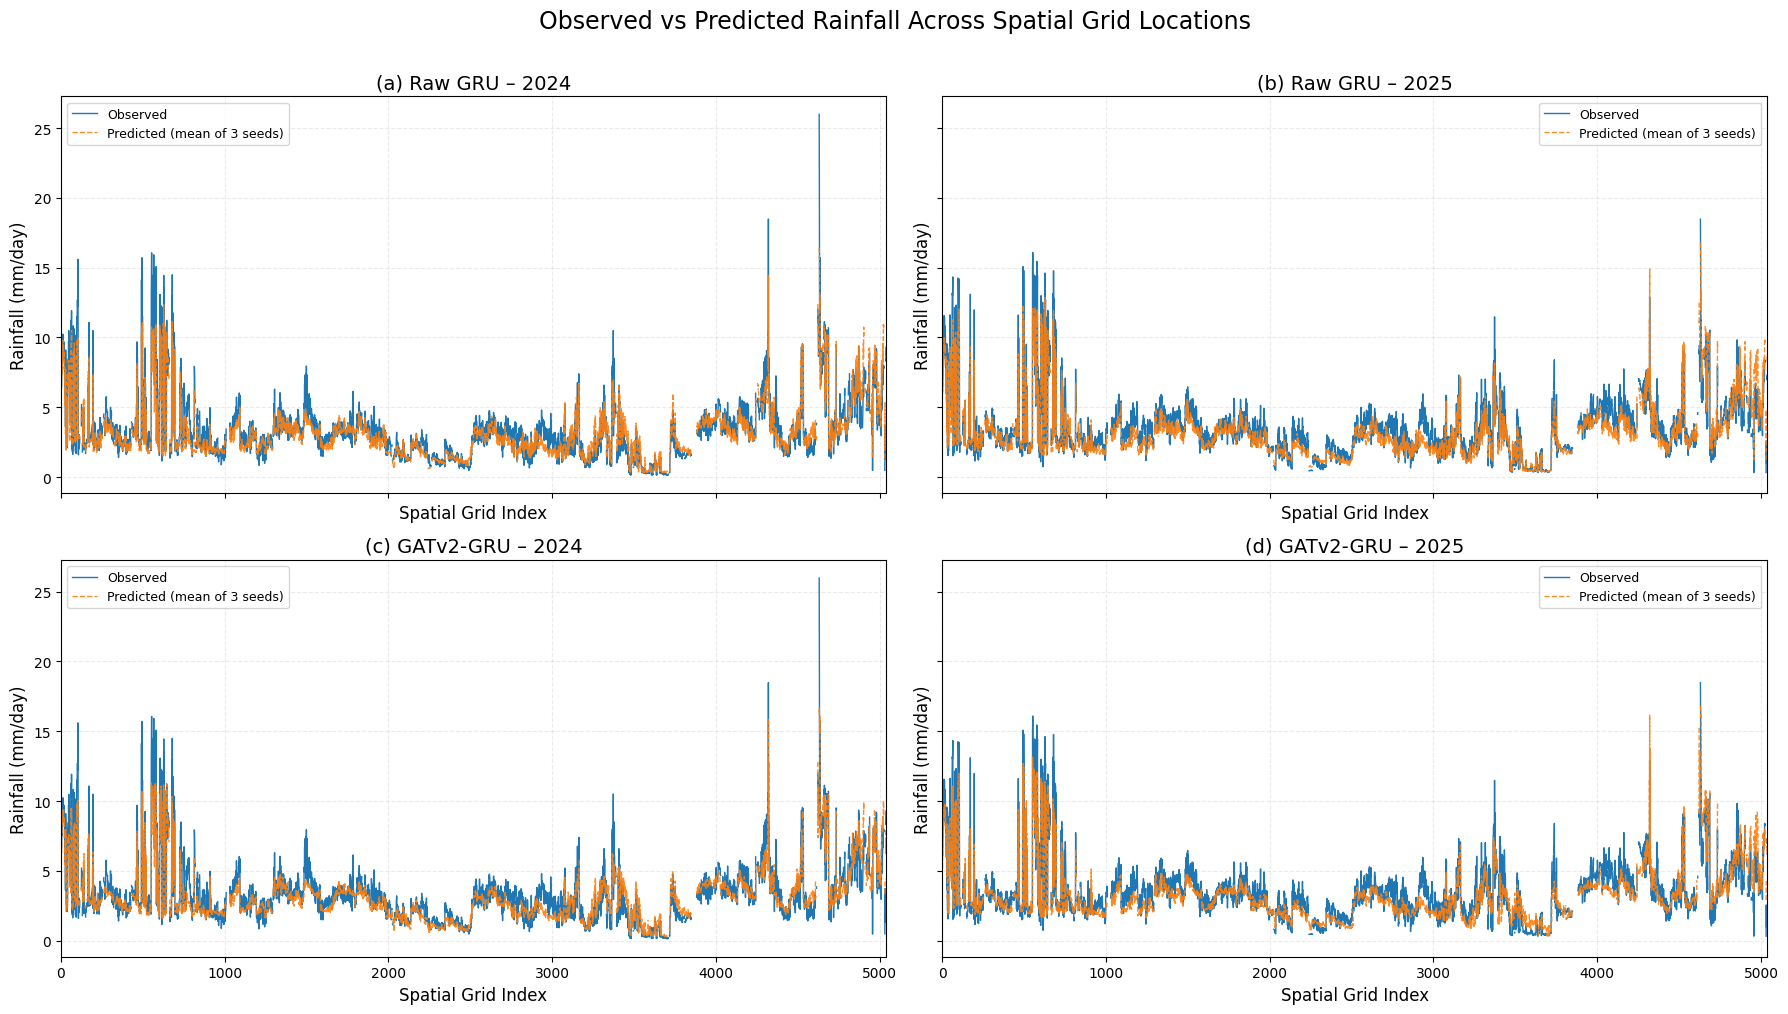


Figure saved: /kaggle/working/final_forecasting_figures/Figure7_Rainfall_Comparison.png


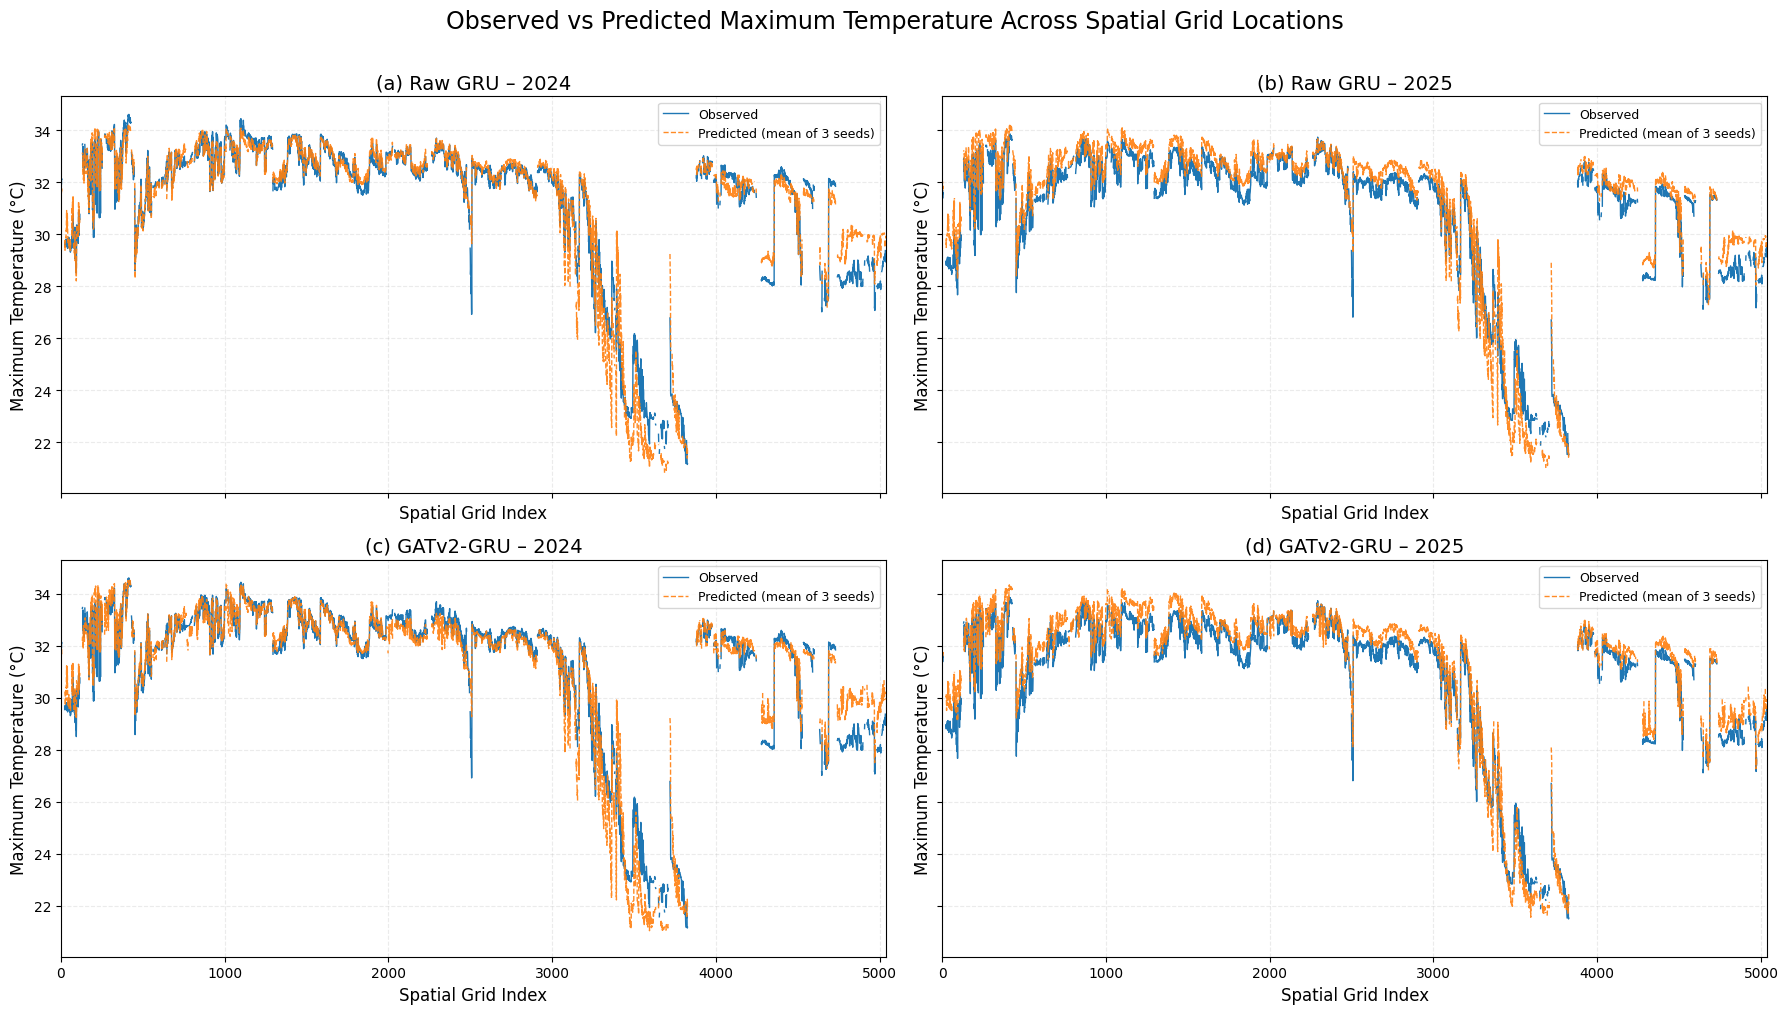


Figure saved: /kaggle/working/final_forecasting_figures/Figure8_Maximum_Temperature_Comparison.png


In [17]:

# ============================================================
# FIGURE GENERATION FUNCTION
# ============================================================

def generate_comparison_figure(
    variable_index,
    variable_name,
    y_axis_label,
    output_filename
):

    fig, axes = plt.subplots(
        nrows=2,
        ncols=2,
        figsize=(18, 10),
        sharex=True,
        sharey=True
    )

    model_information = [
        (
            "Raw GRU",
            mean_raw_gru_prediction
        ),
        (
            "GATv2-GRU",
            mean_gatv2_gru_prediction
        )
    ]

    # --------------------------------------------------------
    # COMMON Y-AXIS RANGE FOR ALL FOUR PANELS
    # --------------------------------------------------------

    valid_observed = Y_test[:, :, variable_index][
        Y_test_mask[:, :, variable_index]
    ]

    valid_raw = mean_raw_gru_prediction[:, :, variable_index][
        Y_test_mask[:, :, variable_index]
    ]

    valid_gat = mean_gatv2_gru_prediction[:, :, variable_index][
        Y_test_mask[:, :, variable_index]
    ]

    all_values = np.concatenate([
        valid_observed,
        valid_raw,
        valid_gat
    ])

    y_min = np.nanmin(all_values)
    y_max = np.nanmax(all_values)

    y_padding = 0.05 * (y_max - y_min)

    if y_padding == 0:
        y_padding = 1.0

    # --------------------------------------------------------
    # PLOT FOUR PANELS
    # --------------------------------------------------------

    panel_labels = ["(a)", "(b)", "(c)", "(d)"]

    panel_number = 0

    for row, (model_name, prediction_array) in enumerate(
        model_information
    ):

        for col, year_index in enumerate(range(2)):

            ax = axes[row, col]

            year = int(target_years[year_index])

            observed = Y_test[
                year_index, :, variable_index
            ]

            predicted = prediction_array[
                year_index, :, variable_index
            ]

            valid_mask = Y_test_mask[
                year_index, :, variable_index
            ]

            # Preserve spatial grid positions.
            # Invalid target locations become NaN and are not plotted.
            observed_plot = np.where(
                valid_mask,
                observed,
                np.nan
            )

            predicted_plot = np.where(
                valid_mask,
                predicted,
                np.nan
            )

            spatial_indices = np.arange(NUM_NODES)

            ax.plot(
                spatial_indices,
                observed_plot,
                label="Observed",
                color="tab:blue",
                linewidth=1.0
            )

            ax.plot(
                spatial_indices,
                predicted_plot,
                label="Predicted (mean of 3 seeds)",
                color="tab:orange",
                linestyle="--",
                linewidth=1.0,
                alpha=0.9
            )

            ax.set_title(
                f"{panel_labels[panel_number]} "
                f"{model_name} – {year}",
                fontsize=14
            )

            ax.set_xlabel(
                "Spatial Grid Index",
                fontsize=12
            )

            ax.set_ylabel(
                y_axis_label,
                fontsize=12
            )

            ax.set_xlim(0, NUM_NODES - 1)

            ax.set_ylim(
                y_min - y_padding,
                y_max + y_padding
            )

            ax.grid(
                True,
                linestyle="--",
                alpha=0.25
            )

            ax.legend(
                fontsize=9,
                loc="best"
            )

            panel_number += 1

    # --------------------------------------------------------
    # FIGURE TITLE AND LAYOUT
    # --------------------------------------------------------

    fig.suptitle(
        f"Observed vs Predicted {variable_name} "
        "Across Spatial Grid Locations",
        fontsize=17,
        y=1.01
    )

    plt.tight_layout()

    # --------------------------------------------------------
    # SAVE HIGH-RESOLUTION FIGURE
    # --------------------------------------------------------

    output_path = os.path.join(
        OUTPUT_DIR,
        output_filename
    )

    plt.savefig(
        output_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    plt.close(fig)

    print("\nFigure saved:", output_path)


# ============================================================
# FIGURE 7: RAINFALL
# ============================================================

generate_comparison_figure(
    variable_index=0,
    variable_name="Rainfall",
    y_axis_label="Rainfall (mm/day)",
    output_filename="Figure7_Rainfall_Comparison.png"
)


# ============================================================
# FIGURE 8: MAXIMUM TEMPERATURE
# ============================================================

generate_comparison_figure(
    variable_index=1,
    variable_name="Maximum Temperature",
    y_axis_label="Maximum Temperature (°C)",
    output_filename="Figure8_Maximum_Temperature_Comparison.png"
)


In [18]:

# ============================================================
# VERIFY FINAL FIGURE FILES
# ============================================================

expected_outputs = [
    "Figure7_Rainfall_Comparison.png",
    "Figure8_Maximum_Temperature_Comparison.png",
    "mean_predictions_2024_2025.npz",
    "figure_generation_metric_check_by_seed.csv",
    "figure_generation_metric_check_summary.csv"
]

print("FINAL OUTPUT VERIFICATION")
print("=" * 65)

for filename in expected_outputs:

    path = os.path.join(OUTPUT_DIR, filename)

    if os.path.exists(path):

        size_mb = os.path.getsize(path) / (1024 ** 2)

        print(
            f"PASS | {filename} | "
            f"{size_mb:.2f} MB"
        )

    else:

        print(f"MISSING | {filename}")

print("\nFigure generation process completed.")


FINAL OUTPUT VERIFICATION
PASS | Figure7_Rainfall_Comparison.png | 3.19 MB
PASS | Figure8_Maximum_Temperature_Comparison.png | 3.21 MB
PASS | mean_predictions_2024_2025.npz | 0.60 MB
PASS | figure_generation_metric_check_by_seed.csv | 0.00 MB
PASS | figure_generation_metric_check_summary.csv | 0.00 MB

Figure generation process completed.
